In [1]:
pip install pandas mysql-connector-python matplotlib seaborn

Defaulting to user installation because normal site-packages is not writeableNote: you may need to restart the kernel to use updated packages.



In [2]:
import mysql.connector
import pandas as pd

connection = mysql.connector.connect(
    host="127.0.0.1",
    user="root",
    password="root",
    database="ecommerce_analysis"
)

print("Connected successfully!")

Connected successfully!


In [3]:
query = "SELECT * FROM customers"

customer_df = pd.read_sql(query, connection)

customer_df.head()

C:\Users\HP\AppData\Local\Temp\ipykernel_13264\3987141209.py:3: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  customer_df = pd.read_sql(query, connection)


,customer_id,customer_name,gender,city,signup_date
0,1001,Customer_1,Male,Pune,11/23/2025
1,1002,Customer_2,Female,Ahmedabad,8/5/2025
2,1003,Customer_3,Female,Indore,10/28/2025
3,1004,Customer_4,Female,Delhi,5/12/2025
4,1005,Customer_5,Male,Bhopal,10/19/2025


In [4]:
customer_df.shape

(250, 5)

In [5]:
customer_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 250 entries, 0 to 249
Data columns (total 5 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   customer_id    250 non-null    int64 
 1   customer_name  250 non-null    object
 2   gender         250 non-null    object
 3   city           250 non-null    object
 4   signup_date    250 non-null    object
dtypes: int64(1), object(4)
memory usage: 9.9+ KB


In [6]:
customer_df

,customer_id,customer_name,gender,city,signup_date
0,1001,Customer_1,Male,Pune,11/23/2025
1,1002,Customer_2,Female,Ahmedabad,8/5/2025
2,1003,Customer_3,Female,Indore,10/28/2025
3,1004,Customer_4,Female,Delhi,5/12/2025
4,1005,Customer_5,Male,Bhopal,10/19/2025
...,...,...,...,...,...
245,1246,Customer_246,Female,Bengaluru,3/26/2026
246,1247,Customer_247,Male,Indore,7/24/2025
247,1248,Customer_248,Female,Jaipur,5/6/2025
248,1249,Customer_249,Female,Mumbai,8/23/2025


In [7]:
customer_df['signup_date']=pd.to_datetime(customer_df['signup_date'])

In [8]:
customer_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 250 entries, 0 to 249
Data columns (total 5 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   customer_id    250 non-null    int64         
 1   customer_name  250 non-null    object        
 2   gender         250 non-null    object        
 3   city           250 non-null    object        
 4   signup_date    250 non-null    datetime64[ns]
dtypes: datetime64[ns](1), int64(1), object(3)
memory usage: 9.9+ KB


In [9]:
customer_df.head()

,customer_id,customer_name,gender,city,signup_date
0,1001,Customer_1,Male,Pune,2025-11-23
1,1002,Customer_2,Female,Ahmedabad,2025-08-05
2,1003,Customer_3,Female,Indore,2025-10-28
3,1004,Customer_4,Female,Delhi,2025-05-12
4,1005,Customer_5,Male,Bhopal,2025-10-19


In [10]:
customer_df.describe()

,customer_id,signup_date
count,250.000000,250
mean,1125.500000,2025-08-20 22:50:52.800000
min,1001.000000,2025-01-01 00:00:00
25%,1063.250000,2025-05-12 06:00:00
50%,1125.500000,2025-08-22 00:00:00
75%,1187.750000,2025-12-11 00:00:00
max,1250.000000,2026-03-27 00:00:00
std,72.312977,NaN


In [11]:
customer_df['gender'].value_counts()

gender
Male      144
Female    106
Name: count, dtype: int64

In [12]:
customer_df['city'].value_counts()

city
Kolkata      39
Pune         29
Ahmedabad    28
Indore       27
Delhi        26
Mumbai       21
Bhopal       20
Hyderabad    20
Bengaluru    19
Jaipur       16
              5
Name: count, dtype: int64

In [13]:
customer_df.duplicated().sum()

np.int64(0)

In [14]:
customer_df['gender'].value_counts(normalize=True) * 100

gender
Male      57.6
Female    42.4
Name: proportion, dtype: float64

In [15]:
customer_df.isnull().sum()

customer_id      0
customer_name    0
gender           0
city             0
signup_date      0
dtype: int64

In [16]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

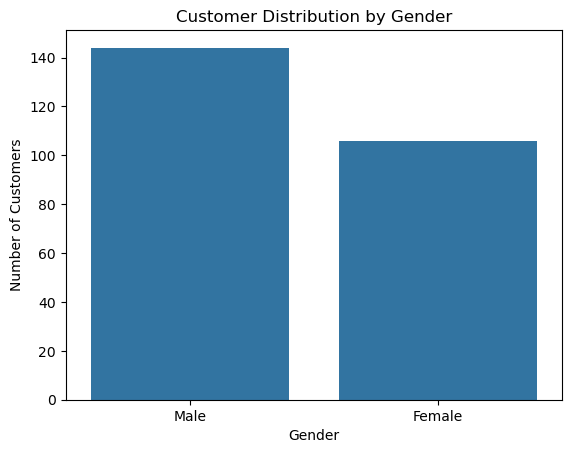

In [17]:
sns.countplot(data=customer_df, x='gender')

plt.title('Customer Distribution by Gender')
plt.xlabel('Gender')
plt.ylabel('Number of Customers')
plt.show()

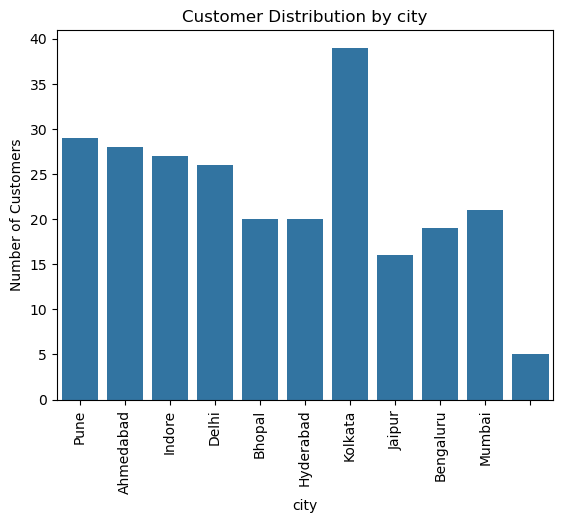

In [18]:
sns.countplot(data=customer_df, x='city')

plt.title('Customer Distribution by city')
plt.xlabel('city')
plt.xticks(rotation='vertical')
plt.ylabel('Number of Customers')
plt.show()

In [19]:
city_count = customer_df['city'].value_counts().head(10)
city_count

city
Kolkata      39
Pune         29
Ahmedabad    28
Indore       27
Delhi        26
Mumbai       21
Bhopal       20
Hyderabad    20
Bengaluru    19
Jaipur       16
Name: count, dtype: int64

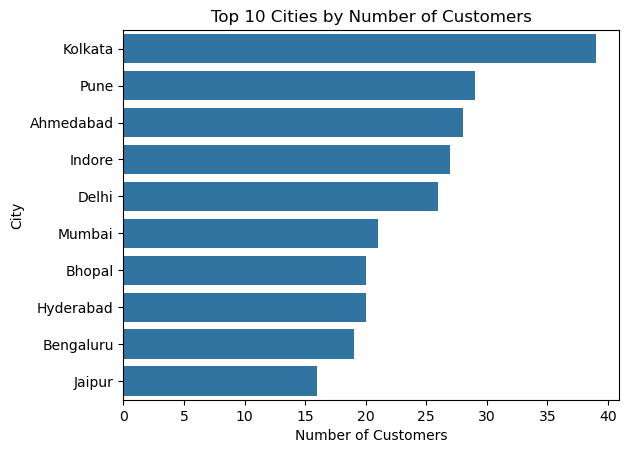

In [20]:
sns.barplot(x=city_count.values, y=city_count.index)

plt.title('Top 10 Cities by Number of Customers')
plt.xlabel('Number of Customers')
plt.ylabel('City')
plt.show()

In [21]:
customer_df['signup_year'] = customer_df['signup_date'].dt.year
yearly_signup = customer_df['signup_year'].value_counts().sort_index()
yearly_signup

signup_year
2025    199
2026     51
Name: count, dtype: int64

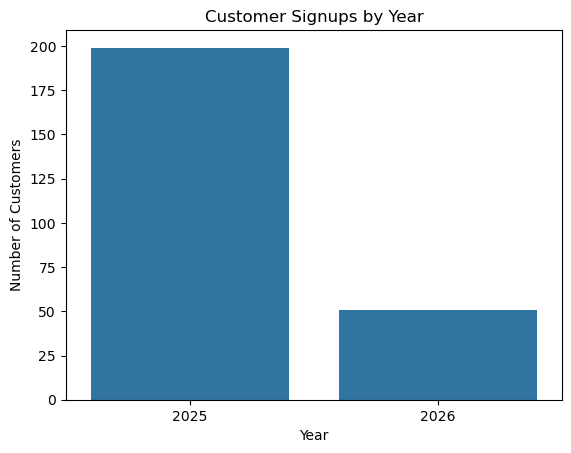

In [22]:
sns.barplot(x=yearly_signup.index, y=yearly_signup.values)

plt.title('Customer Signups by Year')
plt.xlabel('Year')
plt.ylabel('Number of Customers')
plt.show()

In [23]:
customer_df['signup_month'] = customer_df['signup_date'].dt.month
monthly_signup = customer_df['signup_month'].value_counts().sort_index()
monthly_signup

signup_month
1     30
2     38
3     29
4     12
5     19
6     16
7     17
8     21
9     20
10    14
11    15
12    19
Name: count, dtype: int64

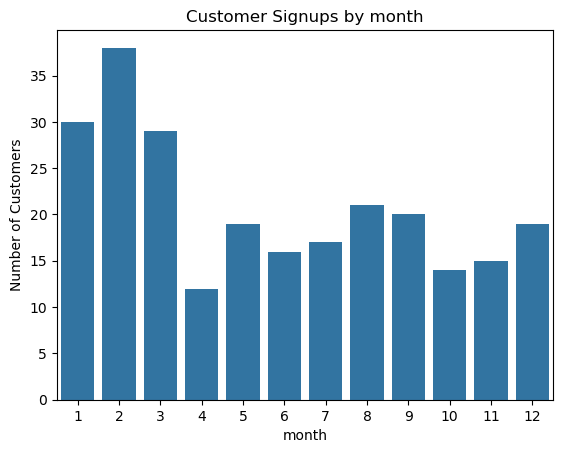

In [24]:
sns.barplot(x=monthly_signup.index, y=monthly_signup.values)

plt.title('Customer Signups by month')
plt.xlabel('month')
plt.ylabel('Number of Customers')
plt.show()

In [25]:
query = "SELECT * FROM orders"

order_df = pd.read_sql(query, connection)

order_df.head()

C:\Users\HP\AppData\Local\Temp\ipykernel_13264\987825002.py:3: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  order_df = pd.read_sql(query, connection)


,order_id,customer_id,order_date,payment_method,order_status
0,50001,1139,2025-05-17,UPI,Completed
1,50002,1064,2025-04-01,Net Banking,Completed
2,50003,1205,2025-06-29,Credit Card,Completed
3,50004,1209,2025-08-20,Cash on Delivery,Returned
4,50005,1072,2026-02-14,Cash on Delivery,Cancelled


In [26]:
order_df.shape

(800, 5)

In [27]:
order_df.describe()

,order_id,customer_id
count,800.0000,800.000000
mean,50400.5000,1123.060000
std,231.0844,71.924911
min,50001.0000,1001.000000
25%,50200.7500,1060.000000
50%,50400.5000,1123.000000
75%,50600.2500,1184.250000
max,50800.0000,1250.000000


In [28]:
order_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 800 entries, 0 to 799
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   order_id        800 non-null    int64 
 1   customer_id     800 non-null    int64 
 2   order_date      800 non-null    object
 3   payment_method  800 non-null    object
 4   order_status    800 non-null    object
dtypes: int64(2), object(3)
memory usage: 31.4+ KB


In [29]:
order_df['order_date']=pd.to_datetime(order_df['order_date'])         

In [30]:
order_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 800 entries, 0 to 799
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   order_id        800 non-null    int64         
 1   customer_id     800 non-null    int64         
 2   order_date      800 non-null    datetime64[ns]
 3   payment_method  800 non-null    object        
 4   order_status    800 non-null    object        
dtypes: datetime64[ns](1), int64(2), object(2)
memory usage: 31.4+ KB


In [31]:
order_df.isnull().sum()

order_id          0
customer_id       0
order_date        0
payment_method    0
order_status      0
dtype: int64

In [32]:
order_df.duplicated().sum()

np.int64(0)

In [33]:
order_df['order_status'].value_counts()

order_status
Completed    661
Cancelled     72
Returned      67
Name: count, dtype: int64

In [34]:
order_df['order_status'].value_counts(normalize=True) * 100

order_status
Completed    82.625
Cancelled     9.000
Returned      8.375
Name: proportion, dtype: float64

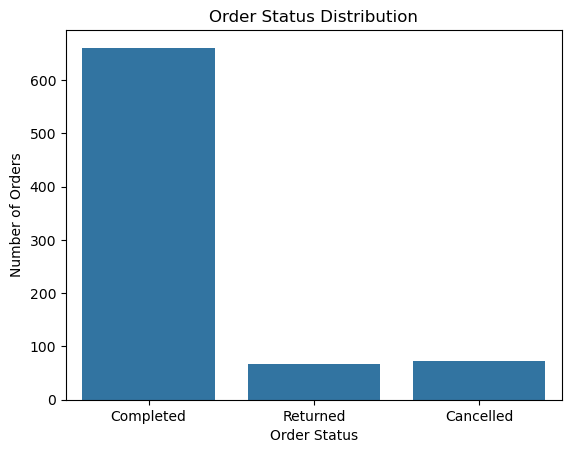

In [35]:
sns.countplot(data=order_df, x='order_status')

plt.title('Order Status Distribution')
plt.xlabel('Order Status')
plt.ylabel('Number of Orders')
plt.show()

In [36]:
order_df['payment_method'].value_counts()

payment_method
UPI                 280
Credit Card         178
Debit Card          148
Cash on Delivery    110
Net Banking          84
Name: count, dtype: int64

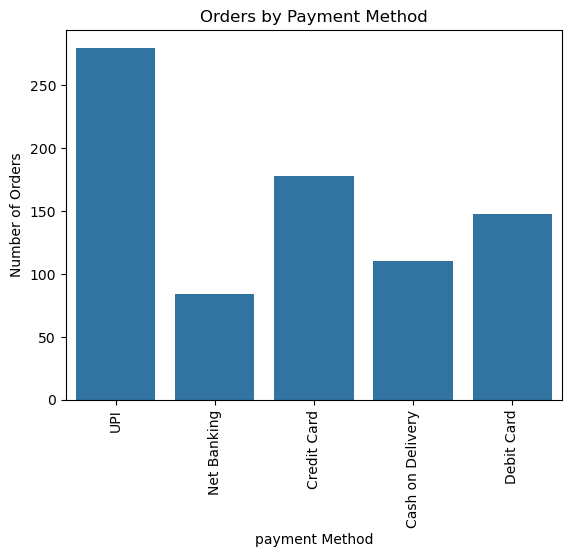

In [37]:
sns.countplot(data=order_df, x='payment_method')

plt.title('Orders by Payment Method')
plt.xlabel('payment Method')
plt.xticks(rotation=90)
plt.ylabel('Number of Orders')
plt.show()

In [38]:
monthly_orders = (
    order_df['order_date']
    .dt.to_period('M')
    .value_counts()
    .sort_index()
)

monthly_orders

order_date
2025-04    79
2025-05    69
2025-06    57
2025-07    62
2025-08    65
2025-09    73
2025-10    52
2025-11    71
2025-12    62
2026-01    75
2026-02    69
2026-03    66
Freq: M, Name: count, dtype: int64

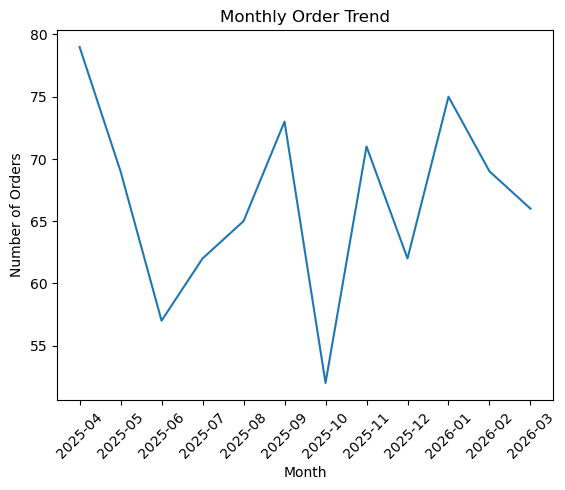

In [39]:
sns.lineplot(
    x=monthly_orders.index.astype(str),
    y=monthly_orders.values
)

plt.title('Monthly Order Trend')
plt.xlabel('Month')
plt.ylabel('Number of Orders')
plt.xticks(rotation=45)
plt.show()

In [40]:
order_df['order_month'] = order_df['order_date'].dt.to_period('M').astype(str)

In [41]:
order_df

,order_id,customer_id,order_date,payment_method,order_status,order_month
0,50001,1139,2025-05-17,UPI,Completed,2025-05
1,50002,1064,2025-04-01,Net Banking,Completed,2025-04
2,50003,1205,2025-06-29,Credit Card,Completed,2025-06
3,50004,1209,2025-08-20,Cash on Delivery,Returned,2025-08
4,50005,1072,2026-02-14,Cash on Delivery,Cancelled,2026-02
...,...,...,...,...,...,...
795,50796,1244,2026-02-13,Credit Card,Completed,2026-02
796,50797,1234,2025-10-31,Debit Card,Completed,2025-10
797,50798,1012,2025-07-26,UPI,Completed,2025-07
798,50799,1239,2026-03-10,Credit Card,Completed,2026-03


In [42]:
monthly_status = (
    order_df
    .groupby(['order_month', 'order_status'])
    .size()
    .reset_index(name='order_count')
)

monthly_status.head()

,order_month,order_status,order_count
0,2025-04,Cancelled,10
1,2025-04,Completed,60
2,2025-04,Returned,9
3,2025-05,Cancelled,8
4,2025-05,Completed,52


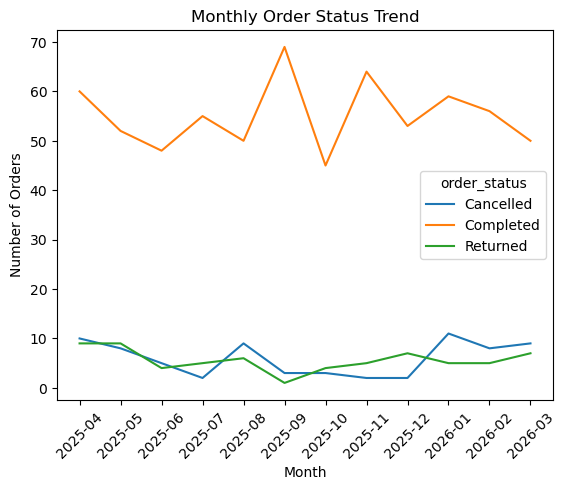

In [43]:
sns.lineplot(
    data=monthly_status,
    x='order_month',
    y='order_count',
    hue='order_status'
)

plt.title('Monthly Order Status Trend')
plt.xlabel('Month')
plt.ylabel('Number of Orders')
plt.xticks(rotation=45)
plt.show()

In [44]:
query = "SELECT * FROM products"
product_df = pd.read_sql(query, connection)

query = "SELECT * FROM order_items"
order_items_df = pd.read_sql(query, connection)

C:\Users\HP\AppData\Local\Temp\ipykernel_13264\2405819539.py:2: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  product_df = pd.read_sql(query, connection)
C:\Users\HP\AppData\Local\Temp\ipykernel_13264\2405819539.py:5: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  order_items_df = pd.read_sql(query, connection)


In [45]:
product_df.head()

,product_id,product_name,category,price
0,2001,Home_Product_1,Home & Kitchen,6346.31
1,2002,Electronics_Product_2,Electronics,36971.50
2,2003,Home_Product_3,Home & Kitchen,11364.53
3,2004,Beauty_Product_4,Beauty,14795.84
4,2005,Electronics_Product_5,Electronics,71774.04


In [46]:
order_items_df.head()

,order_item_id,order_id,product_id,quantity
0,90001,50001,2053,3.0
1,90002,50002,2043,4.0
2,90003,50003,2032,3.0
3,90004,50004,2026,2.0
4,90005,50005,2060,1.0


In [47]:
product_df.shape


(60, 4)

In [48]:
order_items_df.shape

(794, 4)

In [49]:
sales_df = order_df.merge(
    order_items_df,
    on='order_id',
    how='inner'
)

In [50]:
sales_df

,order_id,customer_id,order_date,payment_method,order_status,order_month,order_item_id,product_id,quantity
0,50001,1139,2025-05-17,UPI,Completed,2025-05,90001,2053,3.0
1,50002,1064,2025-04-01,Net Banking,Completed,2025-04,90002,2043,4.0
2,50003,1205,2025-06-29,Credit Card,Completed,2025-06,90003,2032,3.0
3,50004,1209,2025-08-20,Cash on Delivery,Returned,2025-08,90004,2026,2.0
4,50005,1072,2026-02-14,Cash on Delivery,Cancelled,2026-02,90005,2060,1.0
...,...,...,...,...,...,...,...,...,...
789,50796,1244,2026-02-13,Credit Card,Completed,2026-02,90796,2006,1.0
790,50797,1234,2025-10-31,Debit Card,Completed,2025-10,90797,2019,1.0
791,50798,1012,2025-07-26,UPI,Completed,2025-07,90798,2056,2.0
792,50799,1239,2026-03-10,Credit Card,Completed,2026-03,90799,2038,2.0


In [51]:
sales_df = sales_df.merge(
    product_df,
    on='product_id',
    how='inner'
)

In [52]:
sales_df.head()

,order_id,customer_id,order_date,payment_method,order_status,order_month,order_item_id,product_id,quantity,product_name,category,price
0,50001,1139,2025-05-17,UPI,Completed,2025-05,90001,2053,3.0,Electronics_Product_53,Electronics,39412.68
1,50002,1064,2025-04-01,Net Banking,Completed,2025-04,90002,2043,4.0,Fashion_Product_43,Fashion,19774.95
2,50003,1205,2025-06-29,Credit Card,Completed,2025-06,90003,2032,3.0,Electronics_Product_32,Electronics,67304.59
3,50004,1209,2025-08-20,Cash on Delivery,Returned,2025-08,90004,2026,2.0,Home_Product_26,Home & Kitchen,71647.98
4,50005,1072,2026-02-14,Cash on Delivery,Cancelled,2026-02,90005,2060,1.0,Beauty_Product_60,Beauty,19620.06


In [53]:
sales_df['revenue'] = sales_df['quantity'] * sales_df['price']


In [54]:
sales_df[['product_name', 'quantity', 'price', 'revenue']].head()

,product_name,quantity,price,revenue
0,Electronics_Product_53,3.0,39412.68,118238.04
1,Fashion_Product_43,4.0,19774.95,79099.80
2,Electronics_Product_32,3.0,67304.59,201913.77
3,Home_Product_26,2.0,71647.98,143295.96
4,Beauty_Product_60,1.0,19620.06,19620.06


In [55]:
category_revenue = sales_df.groupby('category')['revenue'].sum().sort_values(ascending=False)
category_revenue

category
Fashion           14088634.77
Electronics       13294629.60
Home & Kitchen    12530523.99
Sports            10712612.28
Beauty             8096516.62
Name: revenue, dtype: float64

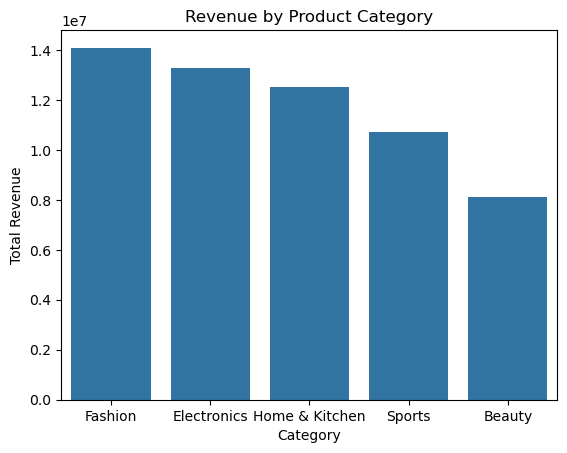

In [56]:
sns.barplot(
    x=category_revenue.index,
    y=category_revenue.values
)

plt.title('Revenue by Product Category')
plt.xlabel('Category')
plt.ylabel('Total Revenue')
plt.show()

In [57]:
sales_df.head()

,order_id,customer_id,order_date,payment_method,order_status,order_month,order_item_id,product_id,quantity,product_name,category,price,revenue
0,50001,1139,2025-05-17,UPI,Completed,2025-05,90001,2053,3.0,Electronics_Product_53,Electronics,39412.68,118238.04
1,50002,1064,2025-04-01,Net Banking,Completed,2025-04,90002,2043,4.0,Fashion_Product_43,Fashion,19774.95,79099.80
2,50003,1205,2025-06-29,Credit Card,Completed,2025-06,90003,2032,3.0,Electronics_Product_32,Electronics,67304.59,201913.77
3,50004,1209,2025-08-20,Cash on Delivery,Returned,2025-08,90004,2026,2.0,Home_Product_26,Home & Kitchen,71647.98,143295.96
4,50005,1072,2026-02-14,Cash on Delivery,Cancelled,2026-02,90005,2060,1.0,Beauty_Product_60,Beauty,19620.06,19620.06


In [58]:
completed_sales = sales_df[
    sales_df['order_status'] == 'Completed'
].copy()

In [59]:
completed_sales.head()

,order_id,customer_id,order_date,payment_method,order_status,order_month,order_item_id,product_id,quantity,product_name,category,price,revenue
0,50001,1139,2025-05-17,UPI,Completed,2025-05,90001,2053,3.0,Electronics_Product_53,Electronics,39412.68,118238.04
1,50002,1064,2025-04-01,Net Banking,Completed,2025-04,90002,2043,4.0,Fashion_Product_43,Fashion,19774.95,79099.80
2,50003,1205,2025-06-29,Credit Card,Completed,2025-06,90003,2032,3.0,Electronics_Product_32,Electronics,67304.59,201913.77
5,50006,1021,2025-05-08,Net Banking,Completed,2025-05,90006,2016,1.0,Fashion_Product_16,Fashion,64013.01,64013.01
6,50007,1018,2026-01-18,Net Banking,Completed,2026-01,90007,2025,4.0,Home_Product_25,Home & Kitchen,20419.22,81676.88


In [60]:
completed_sales.shape

(655, 13)

In [61]:
completed_category_revenue = (
    completed_sales
    .groupby('category')['revenue']
    .sum()
    .sort_values(ascending=False)
)

completed_category_revenue

category
Electronics       11549940.64
Fashion           10799624.70
Home & Kitchen     9619833.25
Sports             8051007.84
Beauty             6719878.66
Name: revenue, dtype: float64

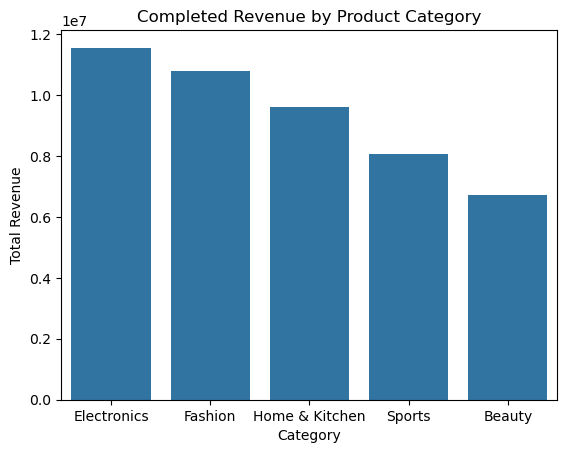

In [62]:
sns.barplot(
    y=completed_category_revenue.values,
    x=completed_category_revenue.index
)

plt.title('Completed Revenue by Product Category')
plt.ylabel('Total Revenue')
plt.xlabel('Category')
plt.show()

In [63]:
product_revenue = (
    completed_sales
    .groupby('product_name')['revenue']
    .sum()
    .sort_values(ascending=False)
)

product_revenue.head(10)

product_name
Electronics_Product_32    2153746.88
Home_Product_54           1840234.48
Fashion_Product_13        1717658.88
Beauty_Product_20         1678410.24
Sports_Product_45         1569020.04
Sports_Product_28         1527174.66
Electronics_Product_17    1433027.44
Electronics_Product_30    1417708.56
Electronics_Product_40    1403907.85
Fashion_Product_23        1399974.35
Name: revenue, dtype: float64

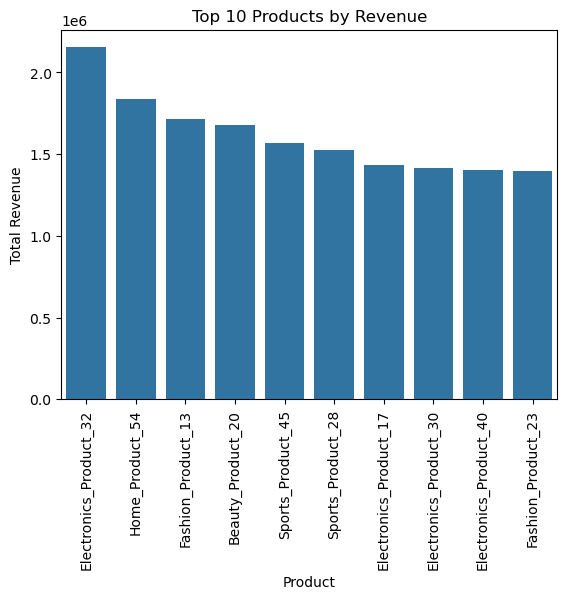

In [64]:
top_10_products = product_revenue.head(10)

sns.barplot(
    y=top_10_products.values,
    x=top_10_products.index
)

plt.title('Top 10 Products by Revenue')
plt.ylabel('Total Revenue')
plt.xlabel('Product')
plt.xticks(rotation=90)
plt.show()

In [65]:
products_quantity = completed_sales.groupby('product_name')['quantity'].sum().sort_values(ascending=False)
top_10_products_quantity = products_quantity.head(10)

In [66]:
top_10_products_quantity

product_name
Beauty_Product_31         34.0
Electronics_Product_32    32.0
Home_Product_59           32.0
Home_Product_8            32.0
Electronics_Product_40    31.0
Fashion_Product_56        30.0
Home_Product_29           29.0
Home_Product_54           28.0
Electronics_Product_17    26.0
Beauty_Product_38         26.0
Name: quantity, dtype: float64

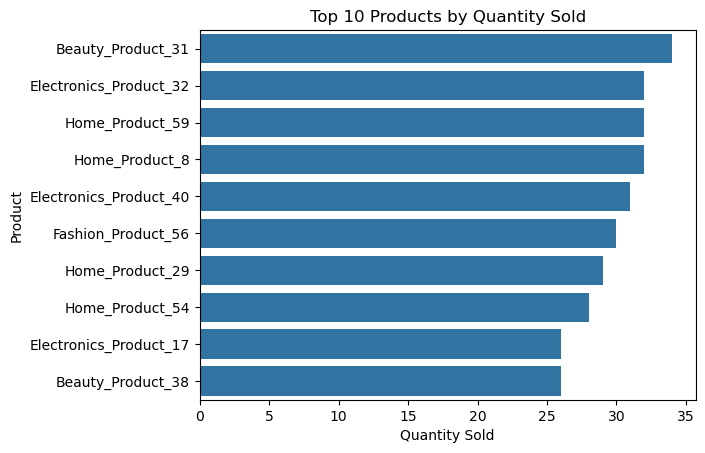

In [67]:
sns.barplot(
    x=top_10_products_quantity.values,
    y=top_10_products_quantity.index
)

plt.title('Top 10 Products by Quantity Sold')
plt.xlabel('Quantity Sold')
plt.ylabel('Product')
plt.show()

In [68]:
completed_sales['order_month'] = (
    completed_sales['order_date']
    .dt.to_period('M')
    .astype(str)
)

In [69]:
completed_sales

,order_id,customer_id,order_date,payment_method,order_status,order_month,order_item_id,product_id,quantity,product_name,category,price,revenue
0,50001,1139,2025-05-17,UPI,Completed,2025-05,90001,2053,3.0,Electronics_Product_53,Electronics,39412.68,118238.04
1,50002,1064,2025-04-01,Net Banking,Completed,2025-04,90002,2043,4.0,Fashion_Product_43,Fashion,19774.95,79099.80
2,50003,1205,2025-06-29,Credit Card,Completed,2025-06,90003,2032,3.0,Electronics_Product_32,Electronics,67304.59,201913.77
5,50006,1021,2025-05-08,Net Banking,Completed,2025-05,90006,2016,1.0,Fashion_Product_16,Fashion,64013.01,64013.01
6,50007,1018,2026-01-18,Net Banking,Completed,2026-01,90007,2025,4.0,Home_Product_25,Home & Kitchen,20419.22,81676.88
...,...,...,...,...,...,...,...,...,...,...,...,...,...
789,50796,1244,2026-02-13,Credit Card,Completed,2026-02,90796,2006,1.0,Home_Product_6,Home & Kitchen,41364.31,41364.31
790,50797,1234,2025-10-31,Debit Card,Completed,2025-10,90797,2019,1.0,Sports_Product_19,Sports,506.82,506.82
791,50798,1012,2025-07-26,UPI,Completed,2025-07,90798,2056,2.0,Fashion_Product_56,Fashion,22614.33,45228.66
792,50799,1239,2026-03-10,Credit Card,Completed,2026-03,90799,2038,2.0,Beauty_Product_38,Beauty,43107.39,86214.78


In [70]:
monthly_revenue = (
    completed_sales
    .groupby('order_month')['revenue']
    .sum()
    .sort_index()
)

monthly_revenue

order_month
2025-04    5046444.96
2025-05    3303174.75
2025-06    3166130.83
2025-07    4098198.21
2025-08    3319227.34
2025-09    5409849.01
2025-10    3077286.38
2025-11    4155437.04
2025-12    4143515.92
2026-01    4269799.13
2026-02    3230830.19
2026-03    3520391.33
Name: revenue, dtype: float64

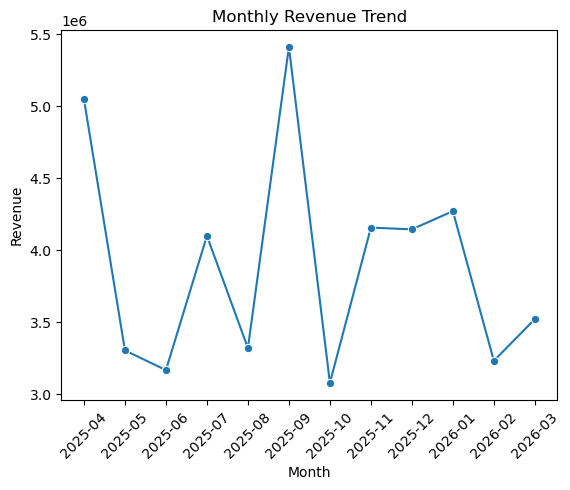

In [71]:
sns.lineplot(
    x=monthly_revenue.index,
    y=monthly_revenue.values,
    marker='o'
)

plt.title('Monthly Revenue Trend')
plt.xlabel('Month')
plt.ylabel('Revenue')
plt.xticks(rotation=45)
plt.show()

#  MoM growth

In [72]:
mom_analysis = pd.DataFrame({
    'monthly_revenue': monthly_revenue,
    'previous_month_revenue': monthly_revenue.shift(1)
})

mom_analysis['growth_percentage'] = (
    (mom_analysis['monthly_revenue'] - mom_analysis['previous_month_revenue'])
    / mom_analysis['previous_month_revenue'].replace(0, np.nan)
    * 100
).round(2)

mom_analysis

,monthly_revenue,previous_month_revenue,growth_percentage
order_month,,,
2025-04,5046444.96,NaN,NaN
2025-05,3303174.75,5046444.96,-34.54
2025-06,3166130.83,3303174.75,-4.15
2025-07,4098198.21,3166130.83,29.44
2025-08,3319227.34,4098198.21,-19.01
2025-09,5409849.01,3319227.34,62.99
2025-10,3077286.38,5409849.01,-43.12
2025-11,4155437.04,3077286.38,35.04
2025-12,4143515.92,4155437.04,-0.29


# running_revenue

In [73]:
running_revenue = pd.DataFrame({
    'monthly_revenue': monthly_revenue,
    'cumulative_revenue': monthly_revenue.cumsum()
})

running_revenue

,monthly_revenue,cumulative_revenue
order_month,,
2025-04,5046444.96,5046444.96
2025-05,3303174.75,8349619.71
2025-06,3166130.83,11515750.54
2025-07,4098198.21,15613948.75
2025-08,3319227.34,18933176.09
2025-09,5409849.01,24343025.10
2025-10,3077286.38,27420311.48
2025-11,4155437.04,31575748.52
2025-12,4143515.92,35719264.44


# Average Order Value (AOV)

In [74]:
order_revenue = (
    completed_sales
    .groupby('order_id')['revenue']
    .sum()
)

order_revenue

order_id
50001    118238.04
50002     79099.80
50003    201913.77
50006     64013.01
50007     81676.88
           ...    
50796     41364.31
50797       506.82
50798     45228.66
50799     86214.78
50800     69417.03
Name: revenue, Length: 655, dtype: float64

In [75]:
aov = round(order_revenue.mean(), 2)

print("Average Order Value:", aov)

Average Order Value: 71359.21


# Top 10 Cities by Completed-Order Revenue

In [76]:
sales_with_customers = completed_sales.merge(
    customer_df[['customer_id', 'city']],
    on='customer_id',
    how='left'
)

In [77]:
city_revenue = (
    sales_with_customers
    .groupby('city')['revenue']
    .sum()
    .sort_values(ascending=False)
)

top_10_cities = city_revenue.head(10)

top_10_cities

city
Kolkata      7206139.46
Delhi        5008109.35
Indore       4807544.44
Pune         4741478.51
Hyderabad    4632482.53
Mumbai       4460234.61
Bengaluru    4374014.37
Ahmedabad    3883740.59
Bhopal       3766573.47
Jaipur       3199459.60
Name: revenue, dtype: float64

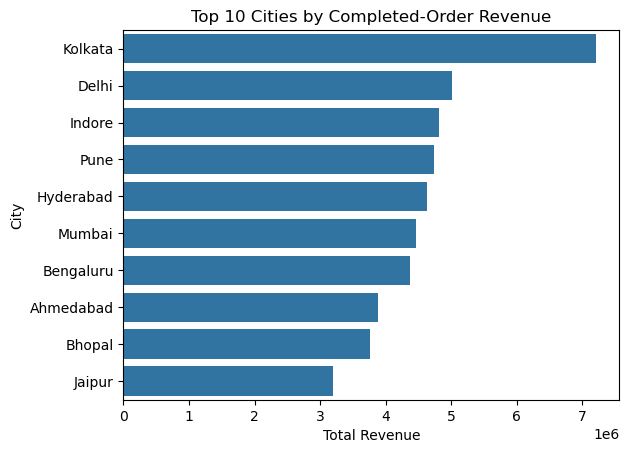

In [78]:
sns.barplot(
    x=top_10_cities.values,
    y=top_10_cities.index
)

plt.title('Top 10 Cities by Completed-Order Revenue')
plt.xlabel('Total Revenue')
plt.ylabel('City')
plt.show()

#  Top 10 Customers by Revenue

In [79]:
sales_with_customers = completed_sales.merge(
    customer_df[['customer_id', 'customer_name']],
    on='customer_id',
    how='left'
)

In [80]:
customer_revenue = (
    sales_with_customers
    .groupby(['customer_id', 'customer_name'])['revenue']
    .sum()
    .sort_values(ascending=False)
)

top_10_customers = customer_revenue.head(10)

top_10_customers

customer_id  customer_name
1049         Customer_49      723031.20
1125         Customer_125     654175.53
1037         Customer_37      640643.94
1136         Customer_136     597692.92
1012         Customer_12      582720.61
1150         Customer_150     578143.25
1021         Customer_21      555318.07
1143         Customer_143     527500.73
1042         Customer_42      526347.61
1178         Customer_178     505484.29
Name: revenue, dtype: float64

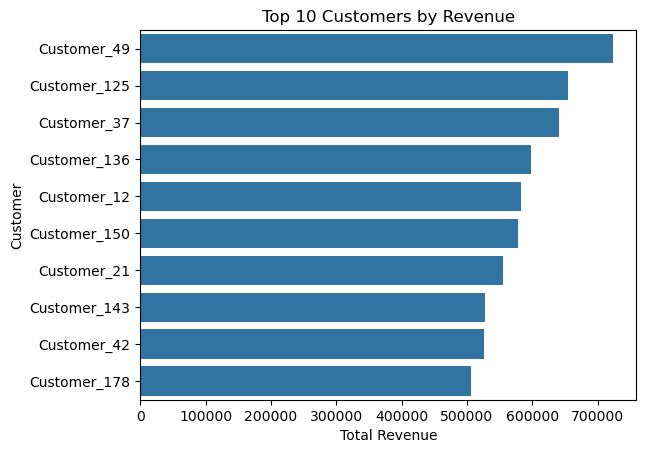

In [81]:
sns.barplot(
    x=top_10_customers.values,
    y=top_10_customers.index.get_level_values('customer_name')
)

plt.title('Top 10 Customers by Revenue')
plt.xlabel('Total Revenue')
plt.ylabel('Customer')
plt.show()

# Top 10 Customers by Number of Completed Orders

In [82]:
customer_orders = (
    completed_sales
    .groupby(['customer_id'])['order_id']
    .nunique()
    .sort_values(ascending=False)
)

top_10_customers_orders = customer_orders.head(10)

top_10_customers_orders

customer_id
1049    8
1119    7
1150    7
1203    7
1037    6
1012    6
1084    6
1108    6
1102    6
1035    6
Name: order_id, dtype: int64

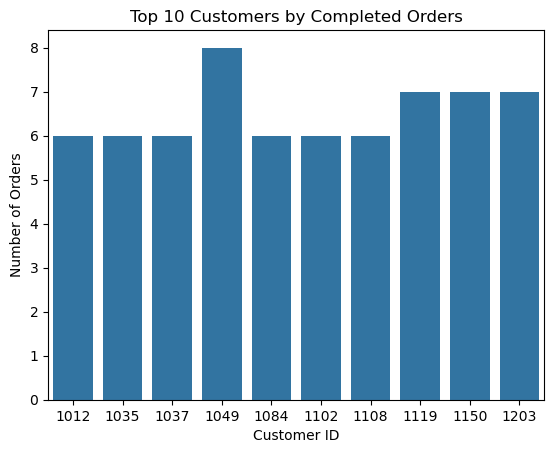

In [83]:
sns.barplot(x=top_10_customers_orders.index, y=top_10_customers_orders.values)

plt.title('Top 10 Customers by Completed Orders')
plt.xlabel('Customer ID')
plt.ylabel('Number of Orders')
plt.show()

#  Repeat vs One-Time Customers

In [84]:
customer_orders = (
    completed_sales.groupby('customer_id')['order_id']
    .nunique()
)

customer_orders

customer_id
1001    4
1002    5
1003    3
1004    1
1005    4
       ..
1245    3
1246    4
1247    2
1248    1
1249    3
Name: order_id, Length: 234, dtype: int64

In [85]:
one_time_customers = (customer_orders == 1).sum()

repeat_customers = (customer_orders > 1).sum()

print("One-time customers:", one_time_customers)
print("Repeat customers:", repeat_customers)

One-time customers: 48
Repeat customers: 186


# Revenue by Payment Method

In [86]:
payment_revenue = (
    completed_sales.groupby('payment_method')['revenue']
    .sum()
    .sort_values(ascending=False)
)

print(payment_revenue)

payment_method
UPI                 16080480.23
Credit Card         10621385.92
Debit Card           8253661.38
Cash on Delivery     6103662.32
Net Banking          5681095.24
Name: revenue, dtype: float64


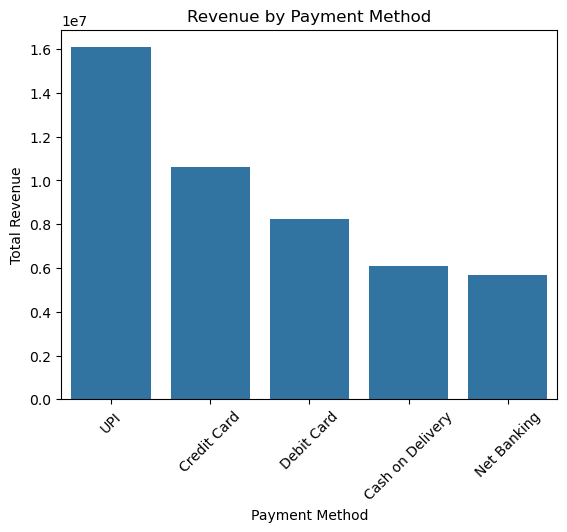

In [87]:
sns.barplot(x=payment_revenue.index, y=payment_revenue.values)

plt.title('Revenue by Payment Method')
plt.xlabel('Payment Method')
plt.ylabel('Total Revenue')
plt.xticks(rotation=45)
plt.show()

# Category Contribution %

In [88]:
category_revenue = (
    completed_sales.groupby('category')['revenue']
    .sum()
    .sort_values(ascending=False)
)

category_contribution = (
    category_revenue / category_revenue.sum()
) * 100

category_contribution = category_contribution.round(2)

print(category_contribution)

category
Electronics       24.71
Fashion           23.11
Home & Kitchen    20.58
Sports            17.22
Beauty            14.38
Name: revenue, dtype: float64


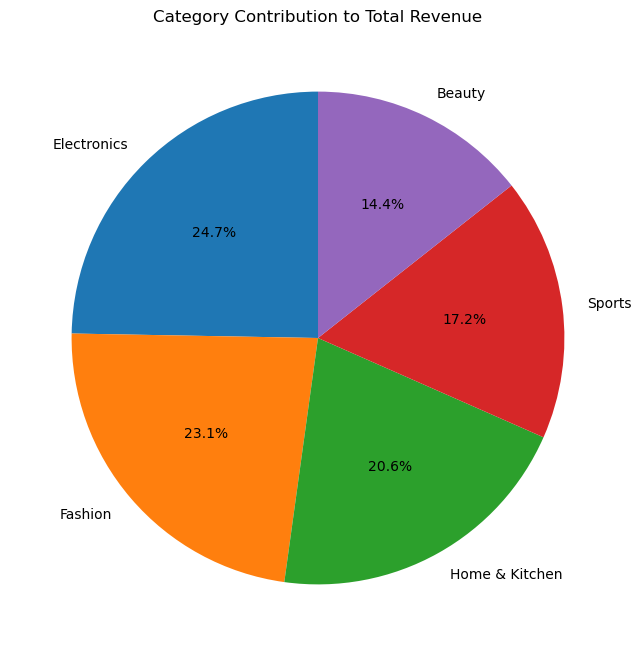

In [89]:
plt.figure(figsize=(8, 8))

plt.pie(
    category_revenue,
    labels=category_revenue.index,
    autopct='%1.1f%%',
    startangle=90
)

plt.title('Category Contribution to Total Revenue')
plt.show()

#  Average Product Price by Category

In [90]:
avg_price_category = (
    product_df.groupby('category')['price']
    .mean()
    .sort_values(ascending=False)
    .round(2)
)

print(avg_price_category)

category
Electronics       49202.99
Fashion           43480.39
Sports            40495.93
Home & Kitchen    38210.00
Beauty            33557.22
Name: price, dtype: float64


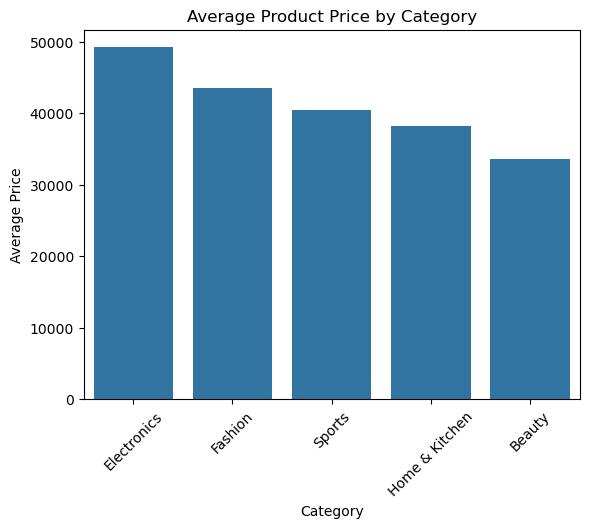

In [91]:
sns.barplot(
    x=avg_price_category.index,
    y=avg_price_category.values
)

plt.title('Average Product Price by Category')
plt.xlabel('Category')
plt.ylabel('Average Price')
plt.xticks(rotation=45)
plt.show()

# Revenue by Order Status

In [92]:
status_revenue = (
    sales_df.groupby('order_status')['revenue']
    .sum()
    .sort_values(ascending=False)
)

print(status_revenue)

order_status
Completed    46740285.09
Returned      6404184.26
Cancelled     5578447.91
Name: revenue, dtype: float64


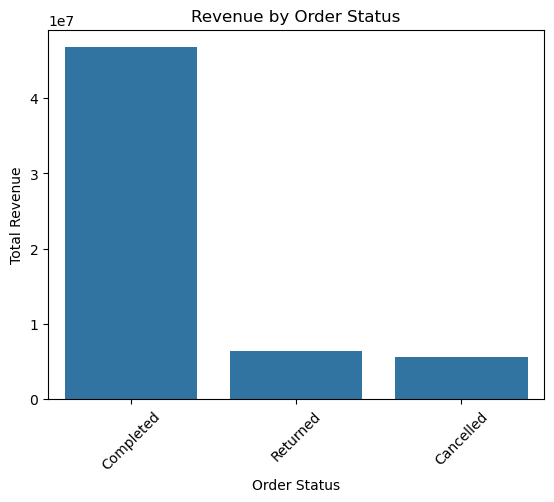

In [93]:
sns.barplot(
    x=status_revenue.index,
    y=status_revenue.values
)

plt.title('Revenue by Order Status')
plt.xlabel('Order Status')
plt.ylabel('Total Revenue')
plt.xticks(rotation=45)
plt.show()

# Top 5 Products by Revenue Within Each Category

In [94]:
product_category_revenue = (
    completed_sales
    .groupby(['category', 'product_name'])['revenue']
    .sum()
    .reset_index()
)

top_5_products = (
    product_category_revenue
    .sort_values(['category', 'revenue'], ascending=[True, False])
    .groupby('category')
    .head(5)
)

print(top_5_products)

          category            product_name     revenue
0           Beauty       Beauty_Product_20  1678410.24
4           Beauty       Beauty_Product_38  1120792.14
6           Beauty       Beauty_Product_42   932032.80
7           Beauty       Beauty_Product_47   885432.08
3           Beauty       Beauty_Product_35   723432.60
15     Electronics  Electronics_Product_32  2153746.88
11     Electronics  Electronics_Product_17  1433027.44
14     Electronics  Electronics_Product_30  1417708.56
17     Electronics  Electronics_Product_40  1403907.85
13     Electronics  Electronics_Product_21  1197576.50
22         Fashion      Fashion_Product_13  1717658.88
24         Fashion      Fashion_Product_23  1399974.35
27         Fashion      Fashion_Product_36   947954.25
23         Fashion      Fashion_Product_16   896182.14
31         Fashion      Fashion_Product_51   831727.26
46  Home & Kitchen         Home_Product_54  1840234.48
45  Home & Kitchen         Home_Product_52  1316337.48
37  Home &

# Revenue by Month and Category

In [95]:
monthly_category_revenue = (
    completed_sales
    .groupby([
        completed_sales['order_date'].dt.to_period('M'),
        'category'
    ])['revenue']
    .sum()
    .reset_index()
)

monthly_category_revenue['order_date'] = (
    monthly_category_revenue['order_date'].astype(str)
)

print(monthly_category_revenue)

   order_date        category     revenue
0     2025-04          Beauty   429225.56
1     2025-04     Electronics   732636.40
2     2025-04         Fashion  1650381.00
3     2025-04  Home & Kitchen  1604350.62
4     2025-04          Sports   629851.38
5     2025-05          Beauty   276155.84
6     2025-05     Electronics   578066.86
7     2025-05         Fashion   961687.00
8     2025-05  Home & Kitchen   764061.58
9     2025-05          Sports   723203.47
10    2025-06          Beauty    99145.78
11    2025-06     Electronics  1503810.34
12    2025-06         Fashion   367082.64
13    2025-06  Home & Kitchen   577873.93
14    2025-06          Sports   618218.14
15    2025-07          Beauty  1180250.55
16    2025-07     Electronics   978057.97
17    2025-07         Fashion   316052.50
18    2025-07  Home & Kitchen  1126010.38
19    2025-07          Sports   497826.81
20    2025-08          Beauty   174620.14
21    2025-08     Electronics   856881.10
22    2025-08         Fashion   98

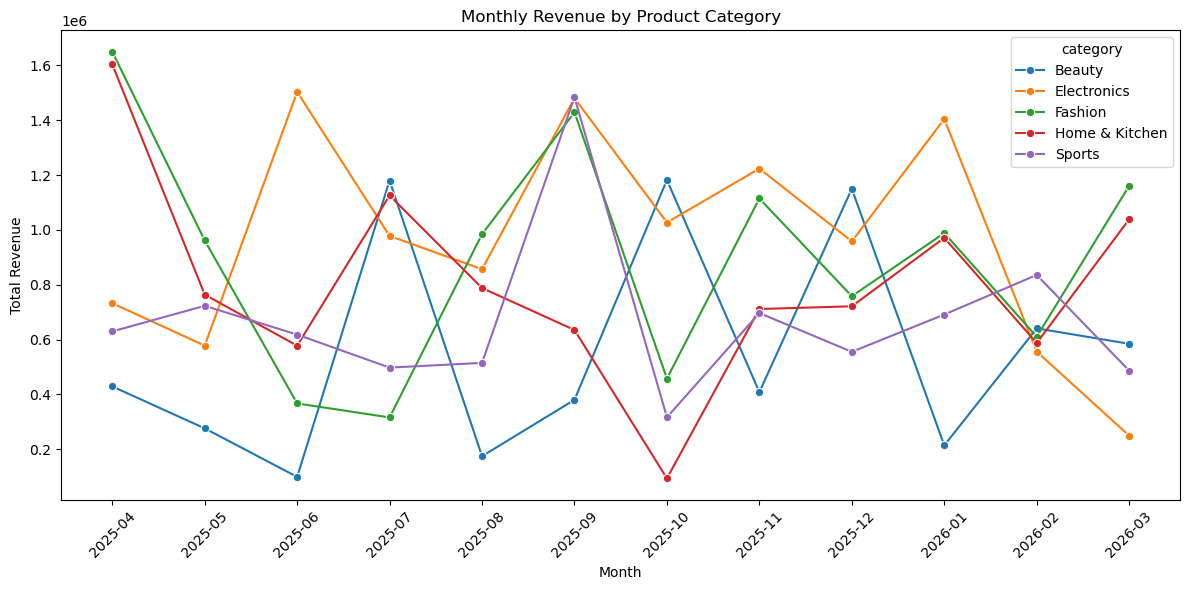

In [96]:
plt.figure(figsize=(12, 6))

sns.lineplot(
    data=monthly_category_revenue,
    x='order_date',
    y='revenue',
    hue='category',
    marker='o'
)

plt.title('Monthly Revenue by Product Category')
plt.xlabel('Month')
plt.ylabel('Total Revenue')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Find the Best-Selling Month

In [97]:
monthly_revenue = (
    completed_sales
    .groupby(completed_sales['order_date'].dt.to_period('M'))['revenue']
    .sum()
    .sort_index()
)

best_month = monthly_revenue.idxmax()
highest_revenue = monthly_revenue.max()

print("Best-Selling Month:", best_month)
print("Total Revenue:", highest_revenue)

Best-Selling Month: 2025-09
Total Revenue: 5409849.01


# Find Repeat Customers' Revenue

In [98]:
customer_orders = (
    completed_sales.groupby('customer_id')['order_id']
    .nunique()
)

repeat_customer_ids = customer_orders[customer_orders > 1].index

repeat_customer_revenue = (
    completed_sales[
        completed_sales['customer_id'].isin(repeat_customer_ids)
    ]['revenue'].sum()
)

print("Revenue from Repeat Customers:", repeat_customer_revenue)

Revenue from Repeat Customers: 43025227.27


# Find Customers Who Have Never Placed a Completed Order

In [99]:
completed_customer_ids = completed_sales['customer_id'].unique()

customers_without_completed_orders = customer_df[
    ~customer_df['customer_id'].isin(completed_customer_ids)
]

print(customers_without_completed_orders)

     customer_id customer_name  gender       city signup_date  signup_year  \
16          1017   Customer_17    Male    Kolkata  2025-01-19         2025   
56          1057   Customer_57    Male     Jaipur  2025-08-17         2025   
80          1081   Customer_81  Female    Kolkata  2025-12-24         2025   
111         1112  Customer_112    Male       Pune  2025-09-10         2025   
112         1113  Customer_113  Female  Ahmedabad  2026-01-25         2026   
139         1140  Customer_140  Female      Delhi  2025-08-05         2025   
154         1155  Customer_155  Female     Indore  2025-05-13         2025   
179         1180  Customer_180    Male     Indore  2025-03-13         2025   
181         1182  Customer_182    Male     Mumbai  2025-06-03         2025   
186         1187  Customer_187  Female  Ahmedabad  2025-09-16         2025   
226         1227  Customer_227  Female      Delhi  2025-12-01         2025   
231         1232  Customer_232    Male    Kolkata  2025-03-22   

In [100]:
print(
    "Customers without completed orders:",
    len(customers_without_completed_orders)
)

Customers without completed orders: 16


# Revenue by Gender 

In [101]:
sales_with_gender = completed_sales.merge(
    customer_df[['customer_id', 'gender']],
    on='customer_id',
    how='left'
)

gender_revenue = (
    sales_with_gender
    .groupby('gender')['revenue']
    .sum()
    .sort_values(ascending=False)
)

print(gender_revenue)

gender
Male      26662411.55
Female    20077873.54
Name: revenue, dtype: float64


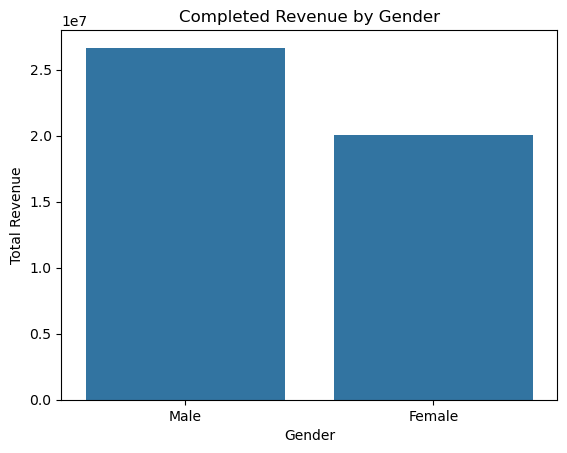

In [102]:
sns.barplot(
    x=gender_revenue.index,
    y=gender_revenue.values
)

plt.title('Completed Revenue by Gender')
plt.xlabel('Gender')
plt.ylabel('Total Revenue')
plt.show()

# Find the Highest-Revenue Product in Each Category

In [103]:
category_product_revenue = (
    completed_sales
    .groupby(['category', 'product_name'])['revenue']
    .sum()
    .reset_index()
)

highest_revenue_products = (
    category_product_revenue
    .sort_values('revenue', ascending=False)
    .groupby('category')
    .head(1)
    .sort_values('category')
)

print(highest_revenue_products)

          category            product_name     revenue
0           Beauty       Beauty_Product_20  1678410.24
15     Electronics  Electronics_Product_32  2153746.88
22         Fashion      Fashion_Product_13  1717658.88
46  Home & Kitchen         Home_Product_54  1840234.48
56          Sports       Sports_Product_45  1569020.04


# Calculate Each Category's Average Order Quantity

In [104]:
avg_quantity_category = (
    completed_sales
    .groupby('category')['quantity']
    .mean()
    .round(2)
    .sort_values(ascending=False)
)

print(avg_quantity_category)

category
Home & Kitchen    1.93
Beauty            1.90
Electronics       1.85
Fashion           1.80
Sports            1.66
Name: quantity, dtype: float64


In [105]:
avg_quantity_per_order = (
    completed_sales
    .groupby(['category', 'order_id'])['quantity']
    .sum()
    .groupby('category')
    .mean()
    .round(2)
    .sort_values(ascending=False)
)

print(avg_quantity_per_order)

category
Home & Kitchen    1.93
Beauty            1.90
Electronics       1.85
Fashion           1.80
Sports            1.66
Name: quantity, dtype: float64


# Find the Top 10 Products by Total Quantity Sold

In [106]:
top_10_quantity_products = (
    completed_sales
    .groupby('product_name')['quantity']
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

print(top_10_quantity_products)

product_name
Beauty_Product_31         34.0
Electronics_Product_32    32.0
Home_Product_59           32.0
Home_Product_8            32.0
Electronics_Product_40    31.0
Fashion_Product_56        30.0
Home_Product_29           29.0
Home_Product_54           28.0
Electronics_Product_17    26.0
Beauty_Product_38         26.0
Name: quantity, dtype: float64


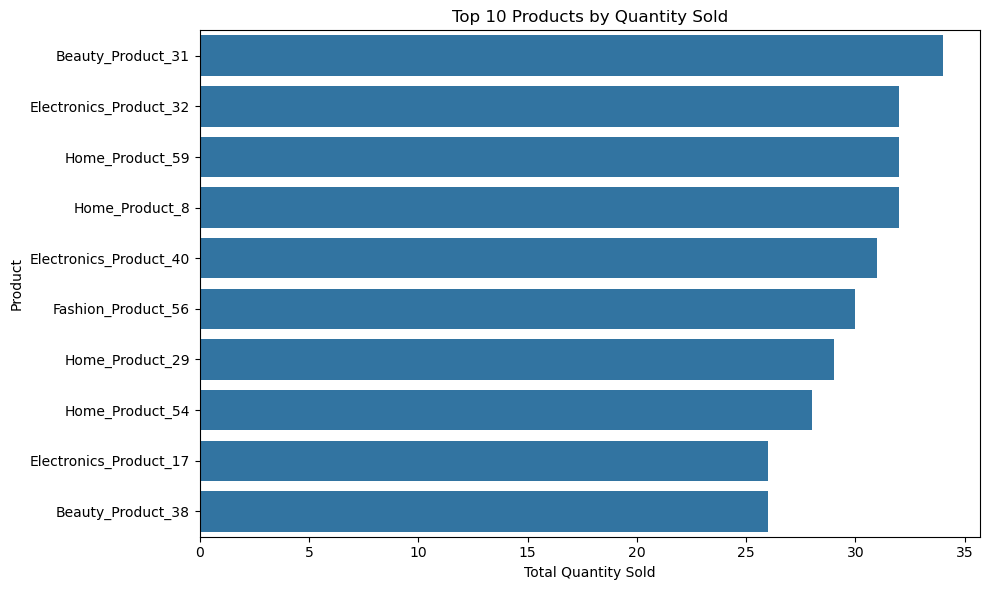

In [107]:
plt.figure(figsize=(10, 6))

sns.barplot(
    x=top_10_quantity_products.values,
    y=top_10_quantity_products.index
)

plt.title('Top 10 Products by Quantity Sold')
plt.xlabel('Total Quantity Sold')
plt.ylabel('Product')
plt.tight_layout()
plt.show()

# Revenue vs. Quantity Sold

In [108]:
product_performance = (
    completed_sales
    .groupby('product_name')
    .agg(
        total_quantity=('quantity', 'sum'),
        total_revenue=('revenue', 'sum')
    )
    .sort_values('total_revenue', ascending=False)
)

print(product_performance)

                        total_quantity  total_revenue
product_name                                         
Electronics_Product_32            32.0     2153746.88
Home_Product_54                   28.0     1840234.48
Fashion_Product_13                24.0     1717658.88
Beauty_Product_20                 26.0     1678410.24
Sports_Product_45                 21.0     1569020.04
Sports_Product_28                 22.0     1527174.66
Electronics_Product_17            26.0     1433027.44
Electronics_Product_30            24.0     1417708.56
Electronics_Product_40            31.0     1403907.85
Fashion_Product_23                23.0     1399974.35
Home_Product_52                   19.0     1316337.48
Electronics_Product_21            25.0     1197576.50
Beauty_Product_38                 26.0     1120792.14
Sports_Product_11                 25.0     1100815.25
Sports_Product_50                 14.0     1100338.12
Home_Product_18                   14.0     1031709.42
Fashion_Product_36          

In [109]:
product_performance['quantity_rank'] = (
    product_performance['total_quantity'].rank(ascending=False)
)

product_performance['revenue_rank'] = (
    product_performance['total_revenue'].rank(ascending=False)
)

high_quantity_low_revenue = (
    product_performance[
        product_performance['quantity_rank'] < product_performance['revenue_rank']
    ]
    .sort_values('total_quantity', ascending=False)
)

print(high_quantity_low_revenue)

                        total_quantity  total_revenue  quantity_rank  \
product_name                                                           
Beauty_Product_31                 34.0       64588.78            1.0   
Home_Product_59                   32.0      518422.40            3.0   
Home_Product_8                    32.0      113831.36            3.0   
Electronics_Product_40            31.0     1403907.85            5.0   
Fashion_Product_56                30.0      678429.90            6.0   
Home_Product_29                   29.0      926664.84            7.0   
Beauty_Product_38                 26.0     1120792.14           10.5   
Beauty_Product_22                 26.0      441613.64           10.5   
Electronics_Product_48            25.0      167365.75           14.0   
Home_Product_25                   24.0      490061.28           18.0   
Electronics_Product_2             24.0      887316.00           18.0   
Sports_Product_15                 24.0      622323.60           

# Find the Revenue Percentage by Payment Method

In [110]:
payment_revenue = (
    completed_sales
    .groupby('payment_method')['revenue']
    .sum()
    .sort_values(ascending=False)
)

payment_contribution = (
    payment_revenue / payment_revenue.sum() * 100
).round(2)

print(payment_contribution)

payment_method
UPI                 34.40
Credit Card         22.72
Debit Card          17.66
Cash on Delivery    13.06
Net Banking         12.15
Name: revenue, dtype: float64


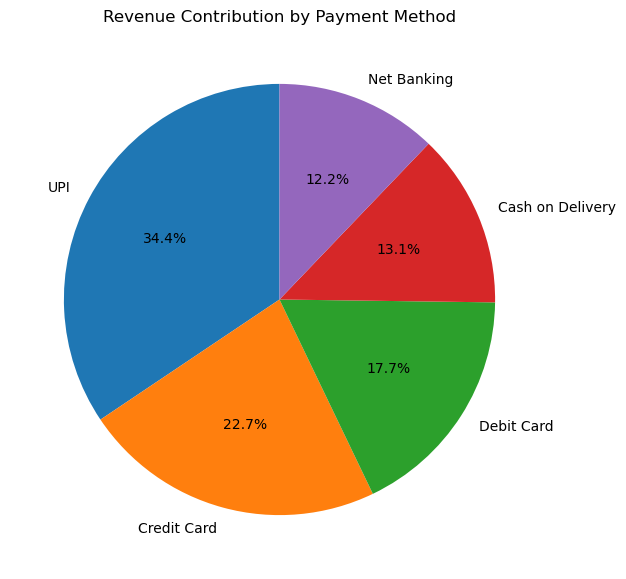

In [111]:
plt.figure(figsize=(7, 7))

plt.pie(
    payment_revenue,
    labels=payment_revenue.index,
    autopct='%1.1f%%',
    startangle=90
)

plt.title('Revenue Contribution by Payment Method')
plt.show()

# Monthly Order Count vs. Monthly Revenue

In [112]:
monthly_summary = (
    completed_sales
    .groupby(completed_sales['order_date'].dt.to_period('M'))
    .agg(
        total_orders=('order_id', 'nunique'),
        total_revenue=('revenue', 'sum')
    )
)

monthly_summary['AOV'] = (
    monthly_summary['total_revenue'] /
    monthly_summary['total_orders']
).round(2)

monthly_summary.index.name = 'month'

print(monthly_summary)

         total_orders  total_revenue       AOV
month                                         
2025-04            60     5046444.96  84107.42
2025-05            51     3303174.75  64768.13
2025-06            47     3166130.83  67364.49
2025-07            55     4098198.21  74512.69
2025-08            50     3319227.34  66384.55
2025-09            69     5409849.01  78403.61
2025-10            45     3077286.38  68384.14
2025-11            64     4155437.04  64928.70
2025-12            53     4143515.92  78179.55
2026-01            57     4269799.13  74908.76
2026-02            56     3230830.19  57693.40
2026-03            48     3520391.33  73341.49


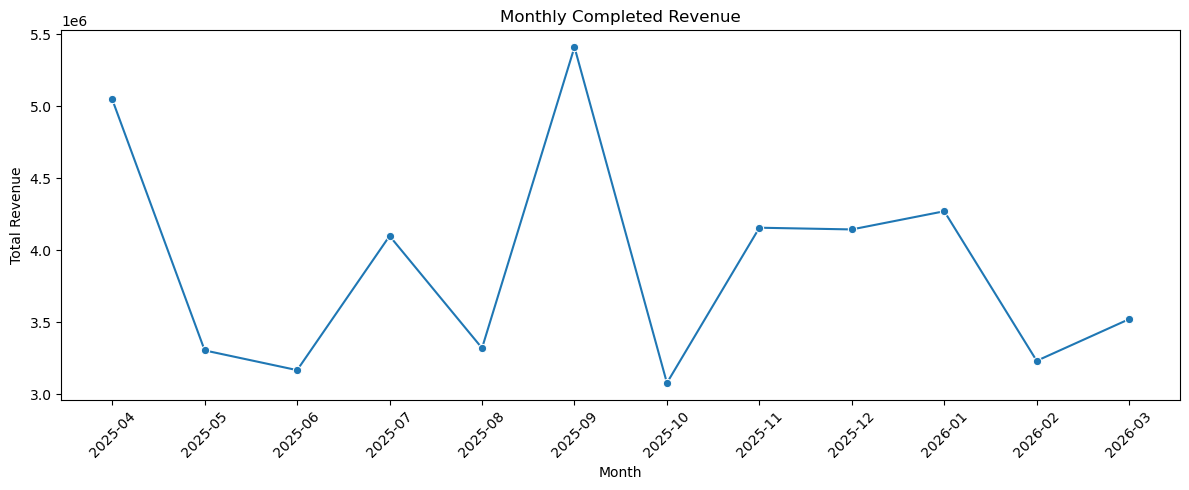

In [113]:
plt.figure(figsize=(12, 5))

sns.lineplot(
    x=monthly_summary.index.astype(str),
    y=monthly_summary['total_revenue'],
    marker='o'
)

plt.title('Monthly Completed Revenue')
plt.xlabel('Month')
plt.ylabel('Total Revenue')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Find the Top 5 Customers by Average Order Value

In [114]:
order_revenue = (
    completed_sales
    .groupby(['customer_id', 'order_id'])['revenue']
    .sum()
    .reset_index()
)

customer_aov = (
    order_revenue
    .groupby('customer_id')['revenue']
    .mean()
    .sort_values(ascending=False)
)

top_5_customers_aov = customer_aov.head(5)

print(top_5_customers_aov)

customer_id
1022    315984.750
1091    298860.960
1079    277668.120
1205    237177.205
1228    224145.720
Name: revenue, dtype: float64


# Final Project Analysis — Key Business Insights

In [115]:
total_revenue = completed_sales['revenue'].sum()

total_orders = completed_sales['order_id'].nunique()

total_customers = completed_sales['customer_id'].nunique()

total_quantity = completed_sales['quantity'].sum()

aov = total_revenue / total_orders if total_orders > 0 else 0

print("===== E-Commerce Business Summary =====")
print("Total Completed Revenue:", round(total_revenue, 2))
print("Total Completed Orders:", total_orders)
print("Unique Customers:", total_customers)
print("Total Quantity Sold:", total_quantity)
print("Average Order Value (AOV):", round(aov, 2))

===== E-Commerce Business Summary =====
Total Completed Revenue: 46740285.09
Total Completed Orders: 655
Unique Customers: 234
Total Quantity Sold: 1200.0
Average Order Value (AOV): 71359.21


In [116]:
kpi_summary = pd.DataFrame({
    'KPI': [
        'Total Completed Revenue',
        'Total Completed Orders',
        'Unique Customers',
        'Total Quantity Sold',
        'Average Order Value'
    ],
    'Value': [
        round(total_revenue, 2),
        total_orders,
        total_customers,
        total_quantity,
        round(aov, 2)
    ]
})

print(kpi_summary)

                       KPI        Value
0  Total Completed Revenue  46740285.09
1   Total Completed Orders       655.00
2         Unique Customers       234.00
3      Total Quantity Sold      1200.00
4      Average Order Value     71359.21
